In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import numpy.ma as ma
from scipy import stats
from matplotlib.lines import Line2D
from pyproj import Transformer

In [2]:
latS,latN,lonW,lonE,latlim,lonlim=dom.coord_domain('MA')
print(latS,latN,lonW,lonE)

latS latN lonW lonE latlim lonlim
10 60 40 130 slice(10, 60, None) slice(40, 130, None)
10 60 40 130


In [3]:
#plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

In [4]:
lev0=850
pre=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/era5/hourly/'
                    +'tp_hourly.era5_MA_201310_201410_202110_202510.nc')
pre=pre.rename({'valid_time':'time'})
pre=pre.tp

In [5]:
year1=2013;
month=10
uv1=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/era5/uv{lev0}_4xdaily_{year1}-10_MA_025x025.nc')
#pre=pre.tp
u1=uv1.u#.mean('time')
v1=uv1.v#.mean('time')
#pre
day1=14
pre_event1= 1000*pre.sel(time=f'{year1}-{month}-{day1}').sum('time')
u_event1 = u1.sel(time=f'{year1}-{month}-{day1}').mean('time')
v_event1 = v1.sel(time=f'{year1}-{month}-{day1}').mean('time')


In [6]:
year2=2014;
month=10
uv2=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/era5/uv{lev0}_4xdaily_{year2}-10_MA_025x025.nc')
#pre=pre.tp
u2=uv2.u#.mean('time')
v2=uv2.v#.mean('time')
#pre
day2=14
pre_event2= 1000*pre.sel(time=f'{year2}-{month}-{day2}').sum('time')
u_event2 = u2.sel(time=f'{year2}-{month}-{day2}').mean('time')
v_event2 = v2.sel(time=f'{year2}-{month}-{day2}').mean('time')


In [7]:
year3=2021;
month=10
uv3=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/era5/uv{lev0}_4xdaily_{year3}-10_MA_025x025.nc')
#pre=pre.tp
u3=uv3.u#.mean('time')
v3=uv3.v#.mean('time')
#pre
day3=19
pre_event3= 1000*pre.sel(time=f'{year3}-{month}-{day3}').sum('time')
u_event3 = u3.sel(time=f'{year3}-{month}-{day3}').mean('time')
v_event3 = v3.sel(time=f'{year3}-{month}-{day3}').mean('time')


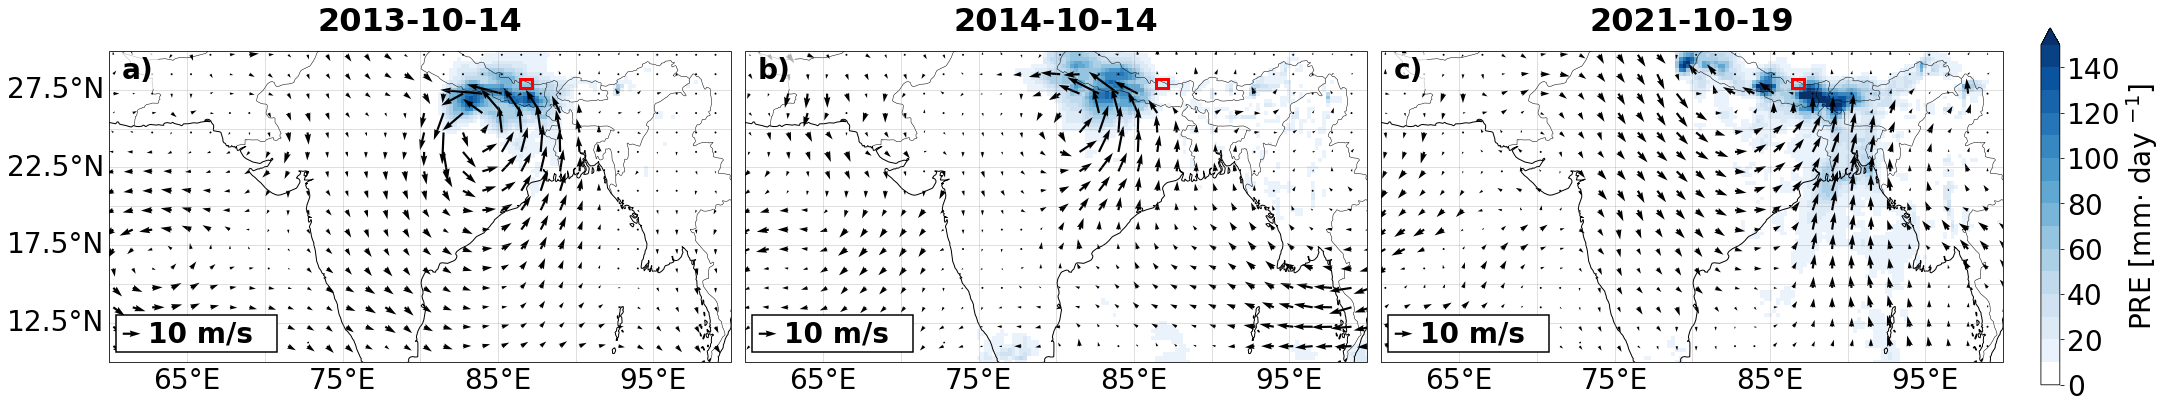

In [8]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
import numpy as np

proj = ccrs.PlateCarree()

fig, axs = plt.subplots(
    1, 3,
    figsize=(30, 10),
    subplot_kw={'projection': proj},
    constrained_layout=True
)
# -----------------------------
# Colormap
# -----------------------------
levels = np.arange(0, 160, 10)

cmap = plt.get_cmap('Blues').copy()
colors = cmap(np.linspace(0, 1, cmap.N))
colors[0] = [1, 1, 1, 1]
cmap_white0 = mcolors.ListedColormap(colors)

norm = mcolors.BoundaryNorm(levels, cmap_white0.N, extend='max')

# -----------------------------
# Lists of events
# -----------------------------
pre_list = [pre_event1, pre_event2, pre_event3]
u_list   = [u_event1, u_event2, u_event3]
v_list   = [v_event1, v_event2, v_event3]

years = [2013, 2014, 2021]
days  = [14, 14, 19]
letters = ['a', 'b', 'c']

skip = 5

for ax, pre_event, u_event, v_event, year, day, letter in zip(
    axs, pre_list, u_list, v_list, years, days, letters
):

    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray')

    c = ax.pcolormesh(
        pre_event.longitude,
        pre_event.latitude,
        pre_event,
        cmap=cmap_white0,
        norm=norm,
        shading='auto',
        transform=ccrs.PlateCarree()
    )

    ax.set_extent([60, 100, 10, 30], crs=ccrs.PlateCarree())

    Q = ax.quiver(
    u_event.longitude[::skip],
    u_event.latitude[::skip],
    u_event[::skip, ::skip],
    v_event[::skip, ::skip],
    transform=ccrs.PlateCarree(),
    scale=350,          # larger arrows
    width=0.0035
    )
    ax.add_patch(
    Rectangle(
        (0.01, 0.03),   # lower-left corner
        0.26,           # width
        0.12,           # height
        transform=ax.transAxes,
        facecolor='white',
        edgecolor='black',
        linewidth=1.5,
        zorder=3
    )
    )

    qk = ax.quiverkey(
    Q,
    X=0.05,
    Y=0.09,
    U=10,
    label='10 m/s',
    labelpos='E',
    coordinates='axes',
    fontproperties={'size':28, 'weight':'bold'}
    )    
    qk.set_zorder(4)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5,
                      color='gray', alpha=0.5)

    gl.top_labels = False
    gl.right_labels = False

    # Only left panel has latitude labels
    if ax != axs[0]:
        gl.left_labels = False

    gl.xlabel_style = {'size':28}
    gl.ylabel_style = {'size':28}
    ax.text(
        0.02, 0.98,
        f'{letter})',
        transform=ax.transAxes,
        fontsize=28,
        fontweight='bold',
        va='top',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )
    ax.set_title(
    f"{year}-{month:02d}-{day:02d}",
    fontsize=32,
    fontweight="bold",
    pad=20
    )
    rect = Rectangle(
        (86.4, 27.6),
        87.2 - 86.4,
        28.2 - 27.6,
        linewidth=3,
        edgecolor='red',
        facecolor='none',
        transform=ccrs.PlateCarree(),
        zorder=10
    )

    ax.add_patch(rect)
    ax.tick_params(labelsize=28)
# -----------------------------
# Shared colorbar
# -----------------------------
cb = fig.colorbar(
    c,
    ax=axs,
    orientation='vertical',
    pad=0.02,
    shrink=0.5,   # shorter (75% of axes height)
    aspect=18      # smaller aspect -> thicker colorbar
)




cb.set_label("PRE [mm$\cdot$ day $^{-1}$]", fontsize=28)
cb.ax.tick_params(labelsize=28)

#plotname = f"FIG11abc_pre_uv{lev0}_events"

#plt.savefig(f"{plotsDir}{plotname}.png", dpi=300, bbox_inches="tight")
#print(plotname)
plt.show()